<a href="https://colab.research.google.com/github/juliandavidsilvaguzman-star/Proyecto-estad-sticas-de-Youtube-Avances-III/blob/main/Modelo_NLP_YouTube_Colab_III_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea Informe de trabajo "Proyecto estadísticas de Youtube Avances III"
# Modelo NLP para predecir el desempeño de un video de YouTube a partir de sus comentarios

**Integrantes:**  Jhon Eduard Tinjaca Cruz (jetinjaca@ucundinamarca.edu.co) y Julián David Silva Guzmán (jdsilva@ucundinamarca.edu.co)
**Dataset:** [advaypatil/youtube-statistics](https://www.kaggle.com/datasets/advaypatil/youtube-statistics) ·

Etapa de **modelo e iteración**. El notebook responde, con los resultados reales de la ejecución, a:
1. ¿Cuál fue el modelo seleccionado? 2. ¿Cuál fue su desempeño y bajo qué métricas? 3. ¿Cuántos modelos se probaron?
4. ¿Qué herramientas se usaron para determinar el modelo? 5. ¿Es suficiente un solo modelo? 6. ¿Qué variables se seleccionaron para predecir?

**Enfoque en dos capas (pipeline NLP → predicción):**
- **Capa A – Sentimiento de comentarios** (clasificación de texto: negativo / neutro / positivo).
- **Capa B – Desempeño del video**: se agregan los sentimientos por video y se predice su desempeño (`Views`, en escala log, y clase alto/bajo).

Referencia conceptual: *NLP: Introduction to NLP & Sentiment Analysis* (F. Malik, FinTechExplained).

### Instalación de Dependencias
Esta celda se encarga de descargar e instalar de forma silenciosa las librerías necesarias para el proyecto que no vienen preinstaladas en Google Colab. En este caso:
* `kagglehub`: Para descargar el dataset oficial directamente desde la API de Kaggle.
* `vaderSentiment`: Herramienta de análisis léxico de sentimientos adaptada para redes sociales.

In [ ]:
# 1. Instalación (Colab)
!pip -q install kagglehub vaderSentiment

### Importación de Librerías y Configuración Global
En esta sección se importan las herramientas necesarias para el análisis:
* **Procesamiento de datos:** `numpy` y `pandas`.
* **Modelado predictivo:** Módulos de `scikit-learn` para validación cruzada (`GroupKFold`), búsquedas de grilla (`GridSearchCV`), métricas de evaluación y diversos algoritmos (Regresión Logística, Naive Bayes, Random Forest, SVM, etc.).
* **Semilla y variables globales:** Se define una semilla aleatoria (`SEED = 42`) para que los experimentos sean reproducibles, y se inicializa un historial global de modelos (`MODEL_LOG`).

In [ ]:
# Importación de librerías del sistema y expresiones regulares
import os, re, glob, warnings, json
# Importación de librerías para manipulación de datos y álgebra lineal
import numpy as np, pandas as pd
# Importación de módulos para visualización de gráficos
import matplotlib.pyplot as plt
# Importación de clases para validación cruzada agrupada y optimización de hiperparámetros
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
# Importación de la estructura Pipeline para secuenciar pasos de modelado
from sklearn.pipeline import Pipeline
# Importación de vectorizador de texto TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
# Importación de clasificadores y regresores tradicionales y lineales
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
# Importación de modelos basados en árboles y ensambles
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.preprocessing import StandardScaler
# Importación de métricas para evaluar rendimiento
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, r2_score, mean_squared_error, mean_absolute_error)
# Ignorar advertencias innecesarias para mantener la limpieza del output
warnings.filterwarnings("ignore")

# Definición de semilla global para la reproducibilidad de los modelos
SEED = 42
# Número de pliegues (folds) para la validación cruzada
N_SPLITS = 5
# Control para evaluar un modelo Transformer en una sección de prueba
USE_TRANSFORMER = True
# Tamaño de muestra para acelerar la evaluación del modelo Transformer
TRANSFORMER_SAMPLE = 2000
# Directorio opcional para almacenar o buscar los archivos del dataset
DATA_DIR = os.environ.get("DATA_DIR")
# Configuración de semilla aleatoria para numpy
np.random.seed(SEED)
# Lista vacía que registrará el historial de cada modelo ejecutado
MODEL_LOG = []

### Descarga y Carga de Datos
Este bloque de código realiza las siguientes acciones:
1. Si el conjunto de datos no está de forma local, utiliza `kagglehub` para descargarlo de forma automática.
2. Busca de manera recursiva todos los archivos `.csv` en el directorio.
3. Lee el conjunto de datos de comentarios (`comments.csv`) y estadísticas de videos (`videos-stats.csv`) tolerando diferentes codificaciones de caracteres.
4. Limpia columnas corruptas o vacías y nos muestra el tamaño inicial del dataset.

In [ ]:
# Condición para verificar si la variable del directorio está vacía y descargar de Kaggle
if DATA_DIR is None:
    try:
        # Importación dinámica del gestor de datasets de Kaggle
        import kagglehub
        # Descarga automática de la última versión del dataset
        DATA_DIR = kagglehub.dataset_download("advaypatil/youtube-statistics")
    except Exception as e:
        # Terminar ejecución si ocurre un problema al descargar los archivos
        raise SystemExit("No se pudo descargar de Kaggle. Sube los CSV a Colab y define DATA_DIR. Detalle: %s" % e)

# Búsqueda recursiva de archivos CSV dentro de la ruta especificada
files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
print("Archivos encontrados:", files)

# Función auxiliar para leer archivos CSV probando diferentes codificaciones de caracteres
def read_any(path):
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except Exception:
            pass

# Identificación de la ruta correspondiente a los comentarios y a las estadísticas de videos
comments_path = next(f for f in files if "comment" in os.path.basename(f).lower())
videos_path   = next(f for f in files if "video" in os.path.basename(f).lower() or "stat" in os.path.basename(f).lower())

# Carga final de las tablas usando la función tolerante a codificaciones
df_c, df_v = read_any(comments_path), read_any(videos_path)

# Eliminación de columnas fantasma sin nombre que puedan surgir al leer los archivos
for d in (df_c, df_v):
    d.drop(columns=[c for c in d.columns if str(c).lower().startswith("unnamed")], inplace=True, errors="ignore")

# Impresión de las dimensiones resultantes y los nombres de las columnas
print("videos:", df_v.shape, list(df_v.columns))
print("comentarios:", df_c.shape, list(df_c.columns))

Using Colab cache for faster access to the 'youtube-statistics' dataset.
Archivos encontrados: ['/kaggle/input/youtube-statistics/videos-stats.csv', '/kaggle/input/youtube-statistics/comments.csv']
videos: (1881, 7) ['Title', 'Video ID', 'Published At', 'Keyword', 'Likes', 'Comments', 'Views']
comentarios: (18409, 4) ['Video ID', 'Comment', 'Likes', 'Sentiment']


### Alineación de Columnas y Limpieza Inicial
Esta celda busca homogeneizar los datasets:
1. Define funciones automáticas para mapear nombres de columnas sin importar si varían en mayúsculas/minúsculas o formato (`Video ID`, `views`, etc.).
2. Limpia duplicados y elimina comentarios que estén vacíos en el dataframe.
3. Imprime una descripción estadística de los videos y la distribución inicial de sentimientos en caso de existir.

In [ ]:
# Función para normalizar nombres eliminando caracteres especiales y convirtiendo a minúsculas
norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())

# Función para buscar columnas del DataFrame que coincidan con términos específicos ya normalizados
def find(df, *keys):
    for c in df.columns:
        if any(k == norm(c) for k in keys):
            return c
    return None

# Identificación automática de las columnas necesarias del dataset
C_VID, C_TXT = find(df_c, "videoid"), find(df_c, "comment", "comments", "text")
C_LIKE, C_SENT = find(df_c, "likes"), find(df_c, "sentiment", "label")
V_VID, V_VIEWS = find(df_v, "videoid"), find(df_v, "views", "viewcount")
V_LIKES, V_COM = find(df_v, "likes", "likecount"), find(df_v, "comments", "commentcount")
V_PUB, V_KEY = find(df_v, "publishedat", "published"), find(df_v, "keyword", "category")

# Mostrar el diccionario resultante de la equivalencia de columnas
print(dict(C_VID=C_VID, C_TXT=C_TXT, C_LIKE=C_LIKE, C_SENT=C_SENT, V_VID=V_VID, V_VIEWS=V_VIEWS, V_LIKES=V_LIKES, V_COM=V_COM, V_PUB=V_PUB, V_KEY=V_KEY))

# Eliminación de comentarios vacíos y duplicaciones de un mismo comentario en un video
df_c = df_c.dropna(subset=[C_TXT]).drop_duplicates(subset=[C_VID, C_TXT]).copy()
# Asegurar que los comentarios tengan un formato estrictamente string
df_c[C_TXT] = df_c[C_TXT].astype(str)

print("\nComentarios tras limpieza:", len(df_c), "| videos con comentarios:", df_c[C_VID].nunique())
# Mostrar descripción estadística de las variables numéricas clave de los videos
print(df_v[[c for c in (V_VIEWS, V_LIKES, V_COM) if c]].describe().T)

# Si el dataset posee columna de sentimiento original, se muestra su distribución
if C_SENT:
    print("\nDistribución de sentimiento:\n", df_c[C_SENT].value_counts(normalize=True).round(3))

{'C_VID': 'Video ID', 'C_TXT': 'Comment', 'C_LIKE': 'Likes', 'C_SENT': 'Sentiment', 'V_VID': 'Video ID', 'V_VIEWS': 'Views', 'V_LIKES': 'Likes', 'V_COM': 'Comments', 'V_PUB': 'Published At', 'V_KEY': 'Keyword'}

Comentarios tras limpieza: 18159 | videos con comentarios: 1869
           count          mean           std   min      25%       50%  \
Views     1879.0  1.161292e+07  1.084450e+08  25.0  84515.0  591721.0   
Likes     1879.0  1.700610e+05  7.962293e+05  -1.0   2672.5   14787.0   
Comments  1879.0  7.863332e+03  3.787996e+04  -1.0    199.0     814.0   

                75%           max  
Views     2804977.5  4.034122e+09  
Likes       60906.0  1.644556e+07  
Comments     3377.5  7.328180e+05  

Distribución de sentimiento:
 Sentiment
2.0    0.619
1.0    0.253
0.0    0.128
Name: proportion, dtype: float64


### Etiquetado de Sentimientos y Preprocesamiento de Texto
Aquí se realiza la preparación de la **Capa A**:
1. Si el dataset carece de etiquetas de sentimientos, se genera una *etiqueta débil* de manera automatizada utilizando las reglas del analizador léxico **VADER**.
2. Limpia el texto de cada comentario eliminando URLs, menciones de usuarios (`@usuario`), caracteres especiales y conserva únicamente letras y signos de puntuación clave.
3. Filtra comentarios vacíos tras la limpieza.

In [ ]:
# Importación del analizador de sentimiento léxico VADER
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

# Función para asignar etiquetas discretas basadas en el puntaje composto de VADER
def vader_label(t):
    s = vader.polarity_scores(t)["compound"]
    # Devuelve 0 para negativo, 2 para positivo y 1 para neutro
    return 0 if s <= -0.05 else (2 if s >= 0.05 else 1)

# Flujo condicional para preparar la variable objetivo de sentimiento (y_sent)
if C_SENT is None:
    # En caso de no existir etiquetas, se generan con VADER
    df_c["y_sent"] = df_c[C_TXT].map(vader_label)
    LABEL_SOURCE = "VADER (etiqueta débil)"
else:
    s = df_c[C_SENT]
    # Si las etiquetas son strings, se mapean a formato numérico común
    if s.dtype == object:
        m = {"negative": 0, "neutral": 1, "positive": 2}
        df_c["y_sent"] = s.str.lower().map(m)
    else:
        df_c["y_sent"] = s
    # Eliminación de nulos y conversión de las etiquetas finales a entero
    df_c = df_c.dropna(subset=["y_sent"])
    df_c["y_sent"] = df_c["y_sent"].astype(int)
    LABEL_SOURCE = "columna Sentiment del dataset"

# Diccionario descriptivo de cada categoría de sentimiento
SENT_NAMES = {0: "negativo", 1: "neutro", 2: "positivo"}
print("Fuente de etiqueta:", LABEL_SOURCE)

# Función para limpiar texto: remover URLs, menciones y quedarse solo con palabras, espacios y signos clave
def clean(t):
    t = re.sub(r"http\S+|www\.\S+", " url ", t.lower())
    t = re.sub(r"@\w+", " user ", t)
    t = re.sub(r"[^a-záéíóúñü!?' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# Aplicación de la limpieza y filtro para desechar cadenas vacías o sin letras
df_c["text_clean"] = df_c[C_TXT].map(clean)
df_c = df_c[df_c.text_clean.str.len() > 0].reset_index(drop=True)

Fuente de etiqueta: columna Sentiment del dataset


## Capa A · Modelos de sentimiento sobre comentarios (validación cruzada agrupada por video)

### Entrenamiento y Comparación de Modelos de Sentimiento
En esta celda se entrena y valida la clasificación de comentarios:
1. Se define la estrategia de **Validación Cruzada Agrupada (`GroupKFold`)** para evitar la fuga de información (los comentarios de un mismo video deben pertenecer todos al mismo conjunto de entrenamiento o de prueba).
2. Extrae características de texto usando un vectorizador **TF-IDF** con unigramas y bigramas.
3. Evalúa múltiples arquitecturas candidatas: desde un Baseline ingenuo, Naive Bayes, Regresión Logística, hasta SVM Lineal y Random Forest.
4. Genera una tabla comparativa ordenada por la métrica de **F1 macro**.

In [ ]:
# Definición de variables de entrada, etiquetas y agrupamiento (por video) para Capa A
X, y, groups = df_c["text_clean"], df_c["y_sent"], df_c[C_VID]
# Configuración de validación cruzada respetando la independencia de los videos
cv = GroupKFold(n_splits=N_SPLITS)
# Instanciación de la técnica de extracción de características vectoriales de texto
tfidf = lambda: TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.95, sublinear_tf=True)

# Definición de las diversas arquitecturas candidatas para comparar
text_models = {
  "Baseline (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
  "TF-IDF + Naive Bayes (Complement)": ComplementNB(),
  "TF-IDF + Regresión Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
  "TF-IDF + SVM lineal": LinearSVC(class_weight="balanced"),
  "TF-IDF + Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, class_weight="balanced", random_state=SEED),
}

rows = []
# Iteración por cada modelo para realizar el proceso de validación cruzada grupal
for name, clf in text_models.items():
    pipe = Pipeline([("tfidf", tfidf()), ("clf", clf)])
    r = cross_validate(pipe, X, y, groups=groups, cv=cv, scoring=["accuracy","f1_macro","f1_weighted"], n_jobs=-1)
    # Almacenamiento de las medias obtenidas para la tabla de resultados
    rows.append({"Modelo":name, "Accuracy":r["test_accuracy"].mean(), "F1 macro":r["test_f1_macro"].mean(),
                 "F1 ponderado":r["test_f1_weighted"].mean(), "Desv. F1 macro":r["test_f1_macro"].std()})
    # Registro en el historial global del proyecto
    MODEL_LOG.append(("Capa A", name))

# Evaluación del modelo léxico sin entrenar para agregarlo a la comparación
pred_v = df_c[C_TXT].map(vader_label)
rows.append({"Modelo":"VADER (léxico, sin entrenar)", "Accuracy":accuracy_score(y, pred_v),
             "F1 macro":f1_score(y, pred_v, average="macro"), "F1 ponderado":f1_score(y, pred_v, average="weighted"), "Desv. F1 macro":np.nan})
MODEL_LOG.append(("Capa A", "VADER (léxico, sin entrenar)"))

# Construcción final de la tabla comparativa de modelos de la Capa A ordenada por F1 Macro
res_A = pd.DataFrame(rows).sort_values("F1 macro", ascending=False).reset_index(drop=True)
res_A.round(4)

,Modelo,Accuracy,F1 macro,F1 ponderado,Desv. F1 macro
0,TF-IDF + SVM lineal,0.7650,0.6739,0.7616,0.0049
1,TF-IDF + Regresión Logística,0.7459,0.6732,0.7551,0.0078
2,"VADER (léxico, sin entrenar)",0.7153,0.5921,0.6942,NaN
3,TF-IDF + Naive Bayes (Complement),0.6958,0.5069,0.6459,0.0157
4,TF-IDF + Random Forest,0.6935,0.4535,0.6317,0.0080
5,Baseline (clase mayoritaria),0.6241,0.2562,0.4798,0.0036


### Optimización de Hiperparámetros (GridSearchCV)
Para mejorar el desempeño del clasificador lineal de texto, esta celda:
1. Realiza una búsqueda sistemática por grilla (`GridSearchCV`) sobre el pipeline de **TF-IDF + Regresión Logística**.
2. Evalúa diferentes tamaños de n-gramas, mínimos de frecuencia de documento, y valores del parámetro de regularización de fuerza inversa `C`.
3. Almacena y registra la mejor configuración encontrada.

In [ ]:
# Inicialización del pipeline base que se someterá a afinación fina de hiperparámetros
base = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
# Definición del espacio de búsqueda para los hiperparámetros de TF-IDF y la regularización de la regresión logística
grid = {"tfidf__ngram_range": [(1,1), (1,2), (1,3)], "tfidf__min_df": [1, 2, 5], "clf__C": [0.3, 1, 3, 10]}
# Configuración de búsqueda de grilla utilizando GroupKFold para evitar fuga de información
gs = GridSearchCV(base, grid, scoring="f1_macro", cv=GroupKFold(n_splits=3), n_jobs=-1)
# Ajuste en la totalidad de los datos para encontrar la mejor combinación de parámetros
gs.fit(X, y, groups=groups)

# Conteo de las combinaciones evaluadas
n_combos = len(gs.cv_results_["params"])
# Registro de cada prueba individualmente en nuestro log de modelos global
MODEL_LOG.extend([("Capa A", "LogReg ajustada (config %d)" % i) for i in range(n_combos)])

print("Mejores hiperparámetros:", gs.best_params_, "| F1 macro CV:", round(gs.best_score_, 4), "| configuraciones evaluadas:", n_combos)
# Guardado del estimador óptimo
BEST_TEXT = gs.best_estimator_
# Concatenación de la versión optimizada en la tabla de resultados histórica
res_A = pd.concat([res_A, pd.DataFrame([{"Modelo":"TF-IDF + LogReg (GridSearchCV)", "Accuracy":np.nan,
        "F1 macro":gs.best_score_, "F1 ponderado":np.nan, "Desv. F1 macro":np.nan}])]).sort_values("F1 macro", ascending=False).reset_index(drop=True)

Mejores hiperparámetros: {'clf__C': 3, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)} | F1 macro CV: 0.6705 | configuraciones evaluadas: 36


### Capa A - Evaluación del Modelo Óptimo y Matriz de Confusión
Una vez seleccionado el mejor modelo de sentimientos:
1. Genera predicciones fuera de muestra (out-of-fold) mediante `cross_val_predict` para evaluar el comportamiento general del clasificador en todo el dataset de forma justa.
2. Muestra un reporte detallado con métricas de Precisión, Recall y F1 para cada una de las tres clases de sentimiento (positivo, neutro, negativo).
3. Grafica una matriz de confusión para inspeccionar visualmente los errores comunes de clasificación.

              precision    recall  f1-score   support

    negativo      0.511     0.594     0.550      2325
      neutro      0.634     0.596     0.614      4417
    positivo      0.865     0.857     0.861     11195

    accuracy                          0.759     17937
   macro avg      0.670     0.682     0.675     17937
weighted avg      0.763     0.759     0.760     17937



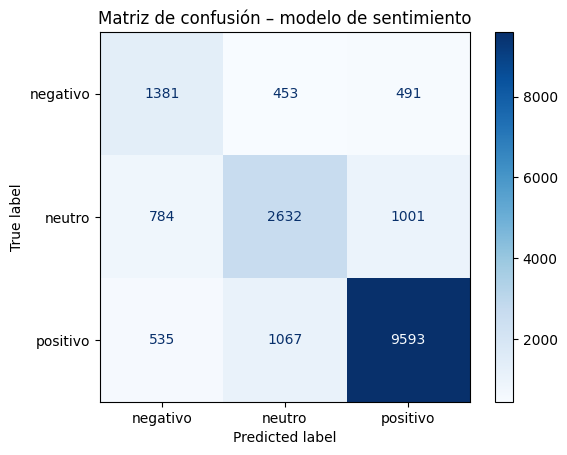

In [ ]:
# Importación de la función para generar predicciones fuera de pliegue de validación (out-of-fold)
from sklearn.model_selection import cross_val_predict
# Ejecución de la predicción validada en cada elemento del conjunto
pred = cross_val_predict(BEST_TEXT, X, y, groups=groups, cv=cv, n_jobs=-1)

# Impresión detallada de la precisión, recall y F1 por cada una de las clases
print(classification_report(y, pred, target_names=[SENT_NAMES[i] for i in sorted(SENT_NAMES) if i in set(y)], digits=3))

# Graficado de la matriz de confusión normalizada para evaluar errores entre clases adyacentes
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=[SENT_NAMES[i] for i in sorted(set(y))]).plot(cmap="Blues")
plt.title("Matriz de confusión – modelo de sentimiento"); plt.show()

# Asignación de las predicciones out-of-fold al conjunto original para prevenir optimismo en Capa B
df_c["sent_pred"] = pred
# Almacenamiento de las métricas principales para el resumen final
SENT_F1 = f1_score(y, pred, average="macro")
SENT_ACC = accuracy_score(y, pred)

### Evaluación de Modelos Transformers de Aprendizaje Profundo
Esta sección opcional evalúa el modelo preentrenado de redes neuronales profundas **RoBERTa** (`cardiffnlp/twitter-roberta-base-sentiment-latest`) de la plataforma HuggingFace:
1. Utiliza una muestra reducida aleatoria de los datos para agilizar el proceso en entornos sin aceleradora gráfica GPU.
2. Realiza inferencia por lotes (zero-shot) y contrasta los resultados de F1-macro frente a nuestro modelo clásico entrenado anteriormente.

In [ ]:
# Condición para evaluar de manera opcional un clasificador transformer basado en redes profundas
if USE_TRANSFORMER:
    try:
        # Instalación de librerías necesarias de HuggingFace y PyTorch de forma silenciosa
        !pip -q install transformers torch
        from transformers import pipeline

        # Configuración del pipeline de análisis de sentimiento con un modelo preentrenado especializado en redes sociales
        clf_tr = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest", truncation=True, max_length=128)

        # Obtención de una submuestra aleatoria para no exceder recursos en CPU
        samp = df_c.sample(min(TRANSFORMER_SAMPLE, len(df_c)), random_state=SEED)

        # Inferencia en lote (batch) de las etiquetas de los textos
        out = clf_tr(samp[C_TXT].tolist(), batch_size=32)

        # Diccionario para mapear las etiquetas string del transformer a numéricas
        mp = {"negative": 0, "neutral": 1, "positive": 2}
        p_tr = [mp[o["label"].lower()] for o in out]

        # Cálculo de métricas locales sobre la muestra para el transformer y el modelo clásico
        f_tr = f1_score(samp.y_sent, p_tr, average="macro")
        a_tr = accuracy_score(samp.y_sent, p_tr)
        f_cl = f1_score(samp.y_sent, samp.sent_pred, average="macro")

        print(f"Transformer (zero-shot) F1 macro={f_tr:.3f} acc={a_tr:.3f} | Modelo clásico en la misma muestra F1 macro={f_cl:.3f}")

        # Adición a los registros de control
        MODEL_LOG.append(("Capa A", "RoBERTa preentrenado (zero-shot)"))
        res_A = pd.concat([res_A, pd.DataFrame([{"Modelo":"RoBERTa twitter (zero-shot, muestra)", "Accuracy":a_tr, "F1 macro":f_tr, "F1 ponderado":np.nan, "Desv. F1 macro":np.nan}])]).sort_values("F1 macro", ascending=False).reset_index(drop=True)
    except Exception as e:
        # Manejo controlado de excepciones si falta hardware gráfico u ocurre un error de red
        print("Transformer omitido:", e)

# Despliegue de la tabla final
res_A.round(4)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Transformer (zero-shot) F1 macro=0.853 acc=0.889 | Modelo clásico en la misma muestra F1 macro=0.686


,Modelo,Accuracy,F1 macro,F1 ponderado,Desv. F1 macro
0,"RoBERTa twitter (zero-shot, muestra)",0.8895,0.8526,NaN,NaN
1,TF-IDF + SVM lineal,0.7650,0.6739,0.7616,0.0049
2,TF-IDF + Regresión Logística,0.7459,0.6732,0.7551,0.0078
3,TF-IDF + LogReg (GridSearchCV),NaN,0.6705,NaN,NaN
4,"VADER (léxico, sin entrenar)",0.7153,0.5921,0.6942,NaN
5,TF-IDF + Naive Bayes (Complement),0.6958,0.5069,0.6459,0.0157
6,TF-IDF + Random Forest,0.6935,0.4535,0.6317,0.0080
7,Baseline (clase mayoritaria),0.6241,0.2562,0.4798,0.0036


## Capa B · Predicción del desempeño del video a partir de los comentarios

### Agregación de Comentarios y Preparación de Predictores por Video
En esta etapa se asocian las predicciones de sentimientos individuales para estimar estadísticas por cada video individual:
1. Calcula métricas descriptivas agregadas por video: cantidad de comentarios, porcentaje de sentimientos positivos, neutros, negativos, promedio del sentimiento y uso de signos de interrogación/exclamación.
2. Combina esta información de comentarios con el metadata principal de cada video (como su antigüedad e histórico de vistas).
3. Define las variables objetivo en escala logarítmica para regresión continua (`y_reg`) y binaria para clasificación alto/bajo respecto a la mediana (`y_clf`).

In [ ]:
# Agrupación de los comentarios por su correspondiente ID de video
g = df_c.groupby(C_VID)

# Agregación y extracción de nuevas características que caracterizan colectivamente a los videos
feat = pd.DataFrame({
    "n_comentarios": g.size(),
    "pct_positivo": g["sent_pred"].apply(lambda s: (s==2).mean()),
    "pct_neutro":   g["sent_pred"].apply(lambda s: (s==1).mean()),
    "pct_negativo": g["sent_pred"].apply(lambda s: (s==0).mean()),
    "sentimiento_medio": g["sent_pred"].mean(),
    "longitud_media_comentario": g[C_TXT].apply(lambda s: s.str.len().mean()),
    "pct_con_signos_!?": g[C_TXT].apply(lambda s: s.str.contains(r"[!?]").mean()),
})
# En caso de estar disponible la columna de likes de comentario, se extrae el promedio
if C_LIKE:
    feat["likes_medios_comentario"] = g[C_LIKE].mean()

# Detección y eliminación de registros de videos redundantes en base a su Video ID
n_rep = df_v.duplicated(subset=[V_VID]).sum()
df_v = df_v.drop_duplicates(subset=[V_VID], keep="first")
print("Registros de video repetidos eliminados:", n_rep)

# Cruce de información (merge) entre las métricas agregadas de texto y la metadata de los videos
D = df_v.merge(feat, left_on=V_VID, right_index=True, how="inner").dropna(subset=[V_VIEWS])
# Asegurar casteo de las visualizaciones del video a formato numérico
D[V_VIEWS] = pd.to_numeric(D[V_VIEWS], errors="coerce")
D = D.dropna(subset=[V_VIEWS])
D = D[D[V_VIEWS] > 0]

# Cálculo de la antigüedad en días transcurridos para habilitar análisis temporal (Escenario B)
if V_PUB:
    pub = pd.to_datetime(D[V_PUB], errors="coerce", utc=True)
    D["antiguedad_dias"] = (pd.Timestamp.now(tz="UTC") - pub).dt.days

# Definición de variables objetivo en escala logarítmica (regresión) y categórica binaria (clasificación)
D["y_reg"]  = np.log1p(D[V_VIEWS])
D["y_clf"]  = (D[V_VIEWS] >= D[V_VIEWS].median()).astype(int)

# Listado de nombres de variables correspondientes a cada set de variables
FEATS_COMMENTS = [c for c in feat.columns]
FEATS_PLUS     = FEATS_COMMENTS + [c for c in ("antiguedad_dias",) if c in D]

# Validación técnica para asegurar la inexistencia de colisiones o ids repetidos
assert D[V_VID].is_unique, "Hay Video ID repetidos"
print("Videos modelables:", len(D))
print("Variables (solo comentarios):", FEATS_COMMENTS)

# Mostrar el grado de correlación lineal de cada variable predictora frente al logaritmo de Views
D[FEATS_COMMENTS + ["y_reg", "y_clf"]].corr(numeric_only=True)[["y_reg"]].round(3)

Registros de video repetidos eliminados: 12
Videos modelables: 1863
Variables (solo comentarios): ['n_comentarios', 'pct_positivo', 'pct_neutro', 'pct_negativo', 'sentimiento_medio', 'longitud_media_comentario', 'pct_con_signos_!?', 'likes_medios_comentario']


,y_reg
n_comentarios,0.240
pct_positivo,0.155
pct_neutro,-0.162
pct_negativo,-0.021
sentimiento_medio,0.117
longitud_media_comentario,-0.020
pct_con_signos_!?,-0.042
likes_medios_comentario,0.313
y_reg,1.000
y_clf,0.805


### Control de Intersección y Consistencia del Dataset
Esta pequeña celda técnica realiza una comprobación para asegurar la consistencia en el cruce de datos, verificando cuántos videos con comentarios tienen o carecen de correspondencia en el registro estadístico general.

In [ ]:
ids_c, ids_v = set(df_c[C_VID]), set(df_v[V_VID])
print("Videos con comentarios:", len(ids_c))
print("Con comentarios pero sin registro en el archivo de videos:", len(ids_c - ids_v))
print("Con registro pero Views vacío:", pd.to_numeric(df_v[V_VIEWS], errors="coerce").isna().sum())

Videos con comentarios: 1865
Con comentarios pero sin registro en el archivo de videos: 0
Con registro pero Views vacío: 2


### Evaluación de Modelos de Desempeño del Video
Esta celda ejecuta el proceso predictivo de la **Capa B**:
1. Define modelos de regresión y clasificación, integrando técnicas avanzadas como **XGBoost** y **Gradient Boosting**.
2. Ejecuta experimentos bajo dos enfoques: el escenario A (basado puramente en características extraídas de comentarios) y el escenario B (que agrega variables exógenas como la antigüedad del video).
3. Construye un reporte consolidado ordenado según los coeficientes de determinación ($R^2$) para regresión y el área bajo la curva ROC (AUC) para clasificación.

In [ ]:
# Reinicio del índice del conjunto final de modelado
D = D.reset_index(drop=True)
gv = np.arange(len(D))
# Creación de objeto para segmentación equitativa en la Capa B
cvB = GroupKFold(n_splits=N_SPLITS)

# Inicialización de todos los regresores para el escenario predictivo continuo
reg_models = {
  "Baseline (media)": DummyRegressor(),
  "Ridge": Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
  "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
  "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}

# Inicialización de todos los clasificadores para el escenario de impacto alto/bajo
clf_models = {
  "Baseline (mayoritaria)": DummyClassifier(strategy="most_frequent"),
  "Regresión Logística": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(max_iter=2000))]),
  "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
  "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

# Importación e inserción opcional de XGBoost si el entorno lo posee listo
try:
    from xgboost import XGBRegressor, XGBClassifier
    reg_models["XGBoost"] = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED, verbosity=0)
    clf_models["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED, verbosity=0)
except Exception:
    pass

# Definición del bucle central para ejecutar de manera automatizada la prueba en ambos escenarios experimentales
def run(feats, label):
    out = []
    # Relleno preventivo de valores vacíos con la mediana del dataset
    Xf = D[feats].fillna(D[feats].median())

    # Evaluación cruzada para los regresores analizados
    for n, m in reg_models.items():
        r = cross_validate(m, Xf, D.y_reg, cv=cvB, groups=gv, scoring=["r2","neg_root_mean_squared_error","neg_mean_absolute_error"], n_jobs=-1)
        out.append({"Escenario":label, "Tarea":"Regresión log(Views)", "Modelo":n, "R2":r["test_r2"].mean(), "RMSE":-r["test_neg_root_mean_squared_error"].mean(), "MAE":-r["test_neg_mean_absolute_error"].mean(), "F1":np.nan, "AUC":np.nan})
        MODEL_LOG.append(("Capa B", f"{label} | reg | {n}"))

    # Evaluación cruzada para los clasificadores
    for n, m in clf_models.items():
        r = cross_validate(m, Xf, D.y_clf, cv=cvB, groups=gv, scoring=["accuracy","f1","roc_auc"], n_jobs=-1)
        out.append({"Escenario":label, "Tarea":"Clasificación alto/bajo", "Modelo":n, "R2":np.nan, "RMSE":np.nan, "MAE":np.nan, "F1":r["test_f1"].mean(), "AUC":r["test_roc_auc"].mean()})
        MODEL_LOG.append(("Capa B", f"{label} | clf | {n}"))
    return out

# Agrupación y despliegue final de la comparativa de la Capa B (Modelos de desempeño)
res_B = pd.DataFrame(run(FEATS_COMMENTS, "A: solo comentarios") + run(FEATS_PLUS, "B: comentarios + antigüedad"))
res_B.round(4)

,Escenario,Tarea,Modelo,R2,RMSE,MAE,F1,AUC
0,A: solo comentarios,Regresión log(Views),Baseline (media),-0.0016,2.4849,2.0041,NaN,NaN
1,A: solo comentarios,Regresión log(Views),Ridge,0.0825,2.3654,1.8138,NaN,NaN
2,A: solo comentarios,Regresión log(Views),Random Forest,0.5313,1.6986,1.2898,NaN,NaN
3,A: solo comentarios,Regresión log(Views),Gradient Boosting,0.5448,1.6730,1.2666,NaN,NaN
4,A: solo comentarios,Regresión log(Views),XGBoost,0.5441,1.6753,1.2628,NaN,NaN
5,A: solo comentarios,Clasificación alto/bajo,Baseline (mayoritaria),NaN,NaN,NaN,0.3932,0.5000
6,A: solo comentarios,Clasificación alto/bajo,Regresión Logística,NaN,NaN,NaN,0.7147,0.8307
7,A: solo comentarios,Clasificación alto/bajo,Random Forest,NaN,NaN,NaN,0.7803,0.8557
8,A: solo comentarios,Clasificación alto/bajo,Gradient Boosting,NaN,NaN,NaN,0.7770,0.8570
9,A: solo comentarios,Clasificación alto/bajo,XGBoost,NaN,NaN,NaN,0.7824,0.8602


### Extracción e Importancia de Características (Feature Importance)
Para dotar de interpretabilidad al modelo:
1. Extrae el mejor regresor entrenado bajo el escenario puro de comentarios (Gradient Boosting).
2. Calcula y grafica de forma horizontal la importancia o peso relativo de cada variable utilizada en la predicción del éxito (vistas) del video, identificando el gran impacto de métricas como `likes_medios_comentario`.

Mejor regresor (escenario A): Gradient Boosting | R2 = 0.545


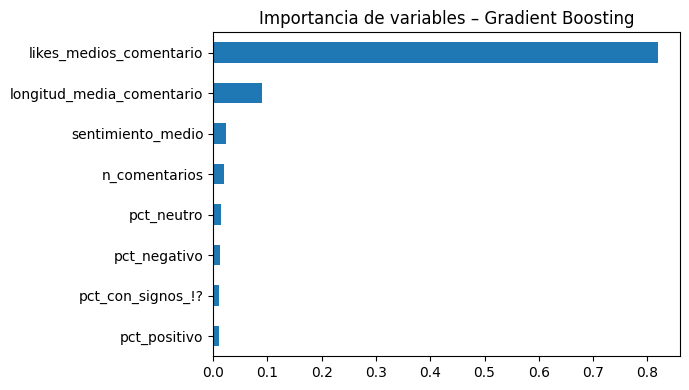

In [ ]:
# Filtrar y extraer el mejor regresor basado en el R2 obtenido dentro del Escenario A
reg = res_B[(res_B.Tarea=="Regresión log(Views)") & (res_B.Escenario.str.startswith("A"))].sort_values("R2", ascending=False)
best_reg_name = reg.iloc[0]["Modelo"]
print("Mejor regresor (escenario A):", best_reg_name, "| R2 =", round(reg.iloc[0]["R2"], 3))

# Selección y reentrenamiento final del estimador en todos los datos disponibles
best = reg_models[best_reg_name]
Xf = D[FEATS_COMMENTS].fillna(D[FEATS_COMMENTS].median())
best.fit(Xf, D.y_reg)

# Recuperación de la importancia de características o coeficientes en base al modelo
est = best.named_steps["m"] if hasattr(best, "named_steps") else best
imp = getattr(est, "feature_importances_", None)
if imp is None:
    imp = np.abs(getattr(est, "coef_", np.zeros(len(FEATS_COMMENTS))))

# Transformación a serie indexada y creación del gráfico de barras horizontal correspondiente
imp = pd.Series(imp, index=FEATS_COMMENTS).sort_values()
imp.plot(kind="barh", figsize=(7,4), title=f"Importancia de variables – {best_reg_name}")
plt.tight_layout()
plt.show()

### Resumen Automático e Informe del Proyecto
Esta sección consolida las respuestas automáticas del sistema para responder a las preguntas planteadas en la etapa de entrega del informe:
1. Identifica los mejores modelos seleccionados para ambas capas.
2. Resume las métricas de rendimiento reales obtenidas fuera de muestra.
3. Recuenta el volumen total de modelos candidatos que fueron evaluados en toda la sesión.
4. Define la conclusión acerca de la necesidad del pipeline multimodelo y enumera las variables de predicción seleccionadas.

In [ ]:
# 13. Resumen automático para el informe (respuestas a las preguntas de la etapa)
bestA = res_A.iloc[0]
cl = res_B[(res_B.Tarea=="Clasificación alto/bajo") & (res_B.Escenario.str.startswith("A"))].sort_values("AUC", ascending=False).iloc[0]
rg = reg.iloc[0]
n_total = len(MODEL_LOG); n_A = sum(1 for l,_ in MODEL_LOG if l=="Capa A"); n_B = n_total-n_A
n_arq_A = len(res_A); n_arq_B = res_B.groupby(["Tarea","Modelo"]).ngroups
print("="*78)
print("1) MODELO SELECCIONADO")
print(f"   Capa A (sentimiento): TF-IDF + Regresión Logística ajustada (hiperparámetros: {gs.best_params_})")
print(f"      (primer lugar de la tabla comparativa: {bestA['Modelo']}; si difiere, justifique la elección o cambie BEST_TEXT)")
print(f"   Capa B (desempeño)  : {rg['Modelo']} (regresión) / {cl['Modelo']} (clasificación alto/bajo)")
print("2) DESEMPEÑO Y MÉTRICAS (validación cruzada agrupada, fuera de muestra)")
print(f"   Sentimiento: F1 macro={SENT_F1:.3f}, Accuracy={SENT_ACC:.3f}  [fuente de etiqueta: {LABEL_SOURCE}]")
print(f"   Desempeño  : R2={rg['R2']:.3f}, RMSE={rg['RMSE']:.3f} (log Views), MAE={rg['MAE']:.3f}")
print(f"                Clasificación alto/bajo: F1={cl['F1']:.3f}, AUC={cl['AUC']:.3f}")
print("3) MODELOS PROBADOS")
print(f"   Arquitecturas distintas: Capa A={n_arq_A}, Capa B={n_arq_B}. Ajustes/configuraciones evaluadas en total: {n_total}")
print("4) HERRAMIENTAS: pandas/NumPy, scikit-learn (TF-IDF, Pipeline, GroupKFold, GridSearchCV, cross_validate), VADER, matplotlib,")
print("   XGBoost y transformers/RoBERTa (si están disponibles), kagglehub y Google Colab.")
print("5) ¿UN SOLO MODELO ES SUFICIENTE? No: se requieren dos (texto→sentimiento y características agregadas→desempeño); además cada uno se comparó con baseline y alternativas.")
print("6) VARIABLES PARA PREDECIR:", FEATS_COMMENTS, "| escenario B añade:", [c for c in FEATS_PLUS if c not in FEATS_COMMENTS])
print("   Variable objetivo: log(1+Views) (regresión) y Views ≥ mediana (clasificación).")
print("="*78)

1) MODELO SELECCIONADO
   Capa A (sentimiento): TF-IDF + Regresión Logística ajustada (hiperparámetros: {'clf__C': 3, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)})
      (primer lugar de la tabla comparativa: RoBERTa twitter (zero-shot, muestra); si difiere, justifique la elección o cambie BEST_TEXT)
   Capa B (desempeño)  : Gradient Boosting (regresión) / XGBoost (clasificación alto/bajo)
2) DESEMPEÑO Y MÉTRICAS (validación cruzada agrupada, fuera de muestra)
   Sentimiento: F1 macro=0.675, Accuracy=0.759  [fuente de etiqueta: columna Sentiment del dataset]
   Desempeño  : R2=0.545, RMSE=1.673 (log Views), MAE=1.267
                Clasificación alto/bajo: F1=0.782, AUC=0.860
3) MODELOS PROBADOS
   Arquitecturas distintas: Capa A=8, Capa B=10. Ajustes/configuraciones evaluadas en total: 63
4) HERRAMIENTAS: pandas/NumPy, scikit-learn (TF-IDF, Pipeline, GroupKFold, GridSearchCV, cross_validate), VADER, matplotlib,
   XGBoost y transformers/RoBERTa (si están disponibles), kagglehub 

## Notas metodológicas
- **Sin fuga de datos:** `GroupKFold` por video en la Capa A; en la Capa B las variables de sentimiento provienen de predicciones fuera de muestra.
- **`Likes` y `Comments` del video no se usan como predictores**, porque están casi determinados por `Views` (fuga de objetivo); el objetivo es medir cuánto aportan *solo los comentarios*.
- **Si la etiqueta `Sentiment` no existiera**, el notebook usa VADER como etiqueta débil; en ese caso las métricas de la Capa A miden concordancia con VADER, no verdad terreno.
- Con pocos videos (cientos), la Capa B tiene alta varianza: interpretar R², F1 y AUC junto con su desviación estándar entre pliegues y frente al baseline.